<a href="https://colab.research.google.com/github/ShanzayIQ/AI651-Assignment2/blob/main/Q2_part1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AI651 Assignment 2 — Question 2: Motion or Memory?
## Part 1 — Setup: data, transformations, windows, Table 1, Figure 1

Run on Colab with a **GPU runtime** (Runtime → Change runtime type → T4 GPU). Part 1 itself only needs CPU, but later parts train models.

Cells are in order — use **Runtime → Run all**.

### 0. Environment and save folder (Google Drive)

In [1]:
# Mount Drive so data, figures and later checkpoints survive Colab disconnects
from google.colab import drive
drive.mount('/content/drive')

import os
ROOT = '/content/drive/MyDrive/AI651_A2_Q2'      # change if you like
DATA_DIR = os.path.join(ROOT, 'data')
FIG_DIR  = os.path.join(ROOT, 'figures')
RES_DIR  = os.path.join(ROOT, 'results')
for d in (DATA_DIR, FIG_DIR, RES_DIR):
    os.makedirs(d, exist_ok=True)
print('Saving everything under', ROOT)

Mounted at /content/drive
Saving everything under /content/drive/MyDrive/AI651_A2_Q2


In [2]:
import json, math, platform, time
import numpy as np
import torch
import torchvision
import cv2
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('torch', torch.__version__, '| torchvision', torchvision.__version__, '| opencv', cv2.__version__)
print('device:', device, '|', torch.cuda.get_device_name(0) if torch.cuda.is_available() else platform.processor())

torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | opencv 5.0.0
device: cuda | Tesla T4


### 1. Load Moving MNIST and split by **video index**
`split=None` gives all 10,000 complete videos, shape `(10000, 20, 1, 64, 64)` uint8.
Split: videos 0–7999 train, 8000–8999 validation, 9000–9999 test.
Frames are kept as uint8 in memory (≈820 MB) and converted to float32/255 when used.

In [3]:
ds = torchvision.datasets.MovingMNIST(root=DATA_DIR, split=None, download=True)
videos_u8 = ds.data                      # (10000, 20, 1, 64, 64) uint8
print('all videos:', tuple(videos_u8.shape), videos_u8.dtype)

train_u8 = videos_u8[0:8000]
val_u8   = videos_u8[8000:9000]
test_u8  = videos_u8[9000:10000]
print('train', tuple(train_u8.shape), '| val', tuple(val_u8.shape), '| test', tuple(test_u8.shape))

def to_float(v_u8):
    """uint8 frames -> float32 in [0, 1]."""
    return v_u8.float() / 255.0

x0 = to_float(train_u8[0])
print('one video as float:', tuple(x0.shape), 'min', x0.min().item(), 'max', x0.max().item())

all videos: (10000, 20, 1, 64, 64) torch.uint8
train (8000, 20, 1, 64, 64) | val (1000, 20, 1, 64, 64) | test (1000, 20, 1, 64, 64)
one video as float: (20, 1, 64, 64) min 0.0 max 1.0


### 2. Transformations: mirror M, rotation R, and the 8 symmetries G
All act on the last two dims (rows, cols), so they work on a frame `(1,64,64)`, a video `(T,1,64,64)` or a batch `(B,T,1,64,64)`.
- `M`: `(Mx)[i,j] = x[i, 63-j]` → `flip` along the column axis.
- `R`: 90° anticlockwise → `torch.rot90(x, k=1, dims=(-2,-1))`.
- `g = (a, m)`: rotate by `R^a` first, then mirror if `m=1`. Inverse: `R^{-a}` when `m=0`; `MR^a` is its own inverse.

In [4]:
def mirror(x):
    return torch.flip(x, dims=(-1,))

def rotate(x, a=1):
    return torch.rot90(x, k=a % 4, dims=(-2, -1))

# The 8 elements of G as (a, m): R^a for m=0, M R^a for m=1
G = [(a, m) for m in (0, 1) for a in range(4)]

def apply_g(x, g):
    a, m = g
    y = rotate(x, a)               # rotate first ...
    return mirror(y) if m else y   # ... then mirror

def apply_g_inv(x, g):
    a, m = g
    if m:                          # M R^a is its own inverse
        return apply_g(x, g)
    return rotate(x, -a)           # (R^a)^{-1} = R^{-a}

def g_name(g):
    a, m = g
    return ('M' if m else '') + (f'R^{a}' if a else ('' if m else 'Id'))

print([g_name(g) for g in G])

['Id', 'R^1', 'R^2', 'R^3', 'M', 'MR^1', 'MR^2', 'MR^3']


### 3. Windows at speed k
Frames are numbered **1–20** (as in the handout). For start `t` and speed `k`:
inputs `t, t+k, …, t+4k`; targets `t+5k, …, t+9k`, keeping only targets ≤ 20.
The function always returns 5 target slots plus a mask, because the model always makes 5 predictions and only existing targets are scored.

In [5]:
N_FRAMES = 20

def window_frames(t, k):
    """1-indexed frame numbers used as input and as (existing) targets."""
    inp = [t + k * i for i in range(5)]
    tgt = [t + k * i for i in range(5, 10) if t + k * i <= N_FRAMES]
    assert inp[-1] <= N_FRAMES, 'input frames must exist'
    return inp, tgt

def get_window(video, t, k=1):
    """video: (20, C, H, W) or (B, 20, C, H, W).
    Returns X (.., 5, C, H, W), Y (.., 5, C, H, W) zero-padded, and mask (5,) bool for existing targets."""
    inp, tgt = window_frames(t, k)
    tdim = video.dim() - 4                 # time axis (0 for one video, 1 for a batch)
    idx = lambda frames: torch.tensor([f - 1 for f in frames], device=video.device)
    X = video.index_select(tdim, idx(inp))
    Y_exist = video.index_select(tdim, idx(tgt))
    pad_shape = list(Y_exist.shape); pad_shape[tdim] = 5 - len(tgt)
    Y = torch.cat([Y_exist, Y_exist.new_zeros(pad_shape)], dim=tdim)
    mask = torch.tensor([True] * len(tgt) + [False] * (5 - len(tgt)))
    return X, Y, mask

# Allowed start frames (handout, 'Windows at different speeds')
def allowed_starts(k, augmented):
    if not augmented:                       # models A, B: 1x only, all 5 targets exist
        assert k == 1
        return [t for t in range(1, N_FRAMES + 1) if t + 9 * k <= N_FRAMES]
    # models C, D: all 5 inputs and at least 2 targets exist
    return [t for t in range(1, N_FRAMES + 1) if t + 6 * k <= N_FRAMES]

print('normal 1x :', allowed_starts(1, False))
for k in (1, 2, 3):
    print(f'augmented {k}x:', allowed_starts(k, True))

normal 1x : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
augmented 1x: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
augmented 2x: [1, 2, 3, 4, 5, 6, 7, 8]
augmented 3x: [1, 2]


### 4. Checking the code → **Table 1**
Uses exactly the functions above (`mirror`, `rotate`, `get_window`).

In [6]:
torch.manual_seed(0)
x = torch.rand(20, 1, 64, 64)              # random video
p = torch.zeros(20, 1, 64, 64)             # marker video
p[7, 0, 10, 20] = 1.0                      # (frame index 7, row 10, column 20), indices from 0

def maxdiff(a, b):
    return (a - b).abs().max().item()

def bright(v):
    f, c, r, col = (v == v.max()).nonzero()[0].tolist()
    return (f, r, col)

lhs_a, lhs_b = mirror(mirror(x)), rotate(x, 4)
lhs_c, rhs_c = mirror(rotate(mirror(x), 1)), rotate(x, -1)

# Video whose frame f is filled with the value f (frames 1..20)
fv = torch.arange(1, 21, dtype=torch.float32).view(20, 1, 1, 1).expand(20, 1, 64, 64).clone()
def frames_used(k):
    X, Y, mask = get_window(fv, t=1, k=k)
    inp = [int(X[i, 0, 0, 0]) for i in range(5)]
    tgt = [int(Y[i, 0, 0, 0]) for i in range(5) if mask[i]]
    return ', '.join(map(str, inp)) + ' / ' + ', '.join(map(str, tgt))

table1 = [
    ('(a) max|M(M(x)) - x|',        '0', f'{maxdiff(lhs_a, x):g}  (equal={torch.equal(lhs_a, x)})'),
    ('(b) max|R^4(x) - x|',         '0', f'{maxdiff(lhs_b, x):g}  (equal={torch.equal(lhs_b, x)})'),
    ('(c) max|MRM(x) - R^-1(x)|',   '0', f'{maxdiff(lhs_c, rhs_c):g}  (equal={torch.equal(lhs_c, rhs_c)})'),
    ('(d) bright pixel of M(p)',    '(7, 10, 43)', str(bright(mirror(p)))),
    ('(e) bright pixel of R(p)',    '(7, 43, 10)', str(bright(rotate(p, 1)))),
    ('(f) 1x input / target',       '1-5 / 6-10', frames_used(1)),
    ('(g) 2x input / target',       '1, 3, 5, 7, 9 / 11, 13, 15, 17, 19', frames_used(2)),
    ('(h) 3x input / target',       '1, 4, 7, 10, 13 / 16, 19', frames_used(3)),
]
print(f'{"Check":30s} | {"Expected":36s} | Yours')
print('-' * 100)
for row in table1:
    print(f'{row[0]:30s} | {row[1]:36s} | {row[2]}')

# hard assertions so later parts never run on broken functions
assert torch.equal(lhs_a, x) and torch.equal(lhs_b, x) and torch.equal(lhs_c, rhs_c)
assert bright(mirror(p)) == (7, 10, 43) and bright(rotate(p, 1)) == (7, 43, 10)
assert frames_used(1) == '1, 2, 3, 4, 5 / 6, 7, 8, 9, 10'
assert frames_used(2) == '1, 3, 5, 7, 9 / 11, 13, 15, 17, 19'
assert frames_used(3) == '1, 4, 7, 10, 13 / 16, 19'
# extra sanity: every g and its inverse
for g in G:
    assert torch.equal(apply_g_inv(apply_g(x, g), g), x), g
print('\nAll Table 1 checks passed (and g^-1(g(x)) = x for all 8 symmetries).')

with open(os.path.join(RES_DIR, 'table1.json'), 'w') as f:
    json.dump(table1, f, indent=1)

Check                          | Expected                             | Yours
----------------------------------------------------------------------------------------------------
(a) max|M(M(x)) - x|           | 0                                    | 0  (equal=True)
(b) max|R^4(x) - x|            | 0                                    | 0  (equal=True)
(c) max|MRM(x) - R^-1(x)|      | 0                                    | 0  (equal=True)
(d) bright pixel of M(p)       | (7, 10, 43)                          | (7, 10, 43)
(e) bright pixel of R(p)       | (7, 43, 10)                          | (7, 43, 10)
(f) 1x input / target          | 1-5 / 6-10                           | 1, 2, 3, 4, 5 / 6, 7, 8, 9, 10
(g) 2x input / target          | 1, 3, 5, 7, 9 / 11, 13, 15, 17, 19   | 1, 3, 5, 7, 9 / 11, 13, 15, 17, 19
(h) 3x input / target          | 1, 4, 7, 10, 13 / 16, 19             | 1, 4, 7, 10, 13 / 16, 19

All Table 1 checks passed (and g^-1(g(x)) = x for all 8 symmetries).


### 5. Is the training data already symmetric? → **Figure 1**
Farneback optical flow on the **first 50 training videos**, all 19 consecutive pairs (950 pairs), on uint8 frames, with exactly the handout's settings.
Keep pixels with intensity > 0.2 (on [0,1]) at the same location in **both** frames and flow magnitude > 0.5 px.
Direction θ = atan2(−dy, dx) in [0°, 360°): 0° = right, 90° = up on screen.

In [7]:
def farneback(prev_u8, next_u8):
    return cv2.calcOpticalFlowFarneback(prev_u8, next_u8, None, 0.5, 3, 15, 3, 5, 1.2, 0)

all_dx, all_dy = [], []
n_pairs = 0
for vid in range(50):
    frames = train_u8[vid, :, 0].numpy()           # (20, 64, 64) uint8 (= float*255)
    frames_f = frames.astype(np.float32) / 255.0
    for s in range(19):                             # pairs (x_s, x_{s+1}), s = 1..19
        flow = farneback(frames[s], frames[s + 1])  # (64, 64, 2): [..., 0] = dx (cols), [..., 1] = dy (rows)
        dx, dy = flow[..., 0], flow[..., 1]
        mag = np.sqrt(dx ** 2 + dy ** 2)
        keep = (frames_f[s] > 0.2) & (frames_f[s + 1] > 0.2) & (mag > 0.5)
        all_dx.append(dx[keep]); all_dy.append(dy[keep])
        n_pairs += 1

dx = np.concatenate(all_dx); dy = np.concatenate(all_dy)
theta = np.degrees(np.arctan2(-dy, dx)) % 360.0
speed = np.sqrt(dx ** 2 + dy ** 2)
n_kept = len(speed)
med_speed = float(np.median(speed))
print(f'frame pairs: {n_pairs} | pixels kept: {n_kept} | median speed: {med_speed:.3f} px/frame')

frame pairs: 950 | pixels kept: 103050 | median speed: 3.318 px/frame


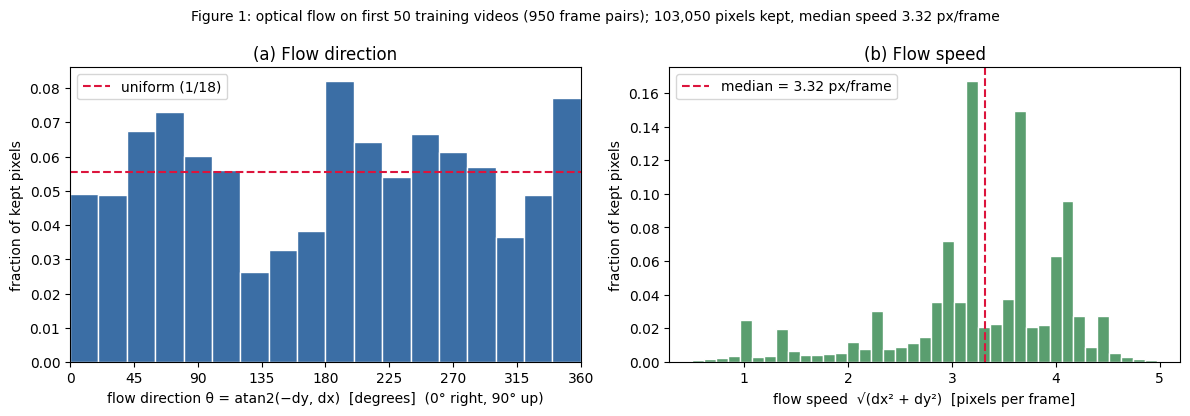

In [8]:
bins_dir = np.arange(0, 361, 20)
w = np.full(n_kept, 1.0 / n_kept)                   # fractions, not counts

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
ax.hist(theta, bins=bins_dir, weights=w, edgecolor='white', color='#3b6ea5')
ax.axhline(1 / 18, color='crimson', ls='--', lw=1.5, label='uniform (1/18)')
ax.set_xticks(range(0, 361, 45)); ax.set_xlim(0, 360)
ax.set_xlabel('flow direction θ = atan2(−dy, dx)  [degrees]  (0° right, 90° up)')
ax.set_ylabel('fraction of kept pixels'); ax.set_title('(a) Flow direction'); ax.legend()

ax = axes[1]
smax = np.percentile(speed, 99.5)
ax.hist(speed, bins=np.linspace(0.5, smax, 40), weights=w, edgecolor='white', color='#5a9e6f')
ax.axvline(med_speed, color='crimson', ls='--', lw=1.5, label=f'median = {med_speed:.2f} px/frame')
ax.set_xlabel('flow speed  √(dx² + dy²)  [pixels per frame]')
ax.set_ylabel('fraction of kept pixels'); ax.set_title('(b) Flow speed'); ax.legend()

fig.suptitle(f'Figure 1: optical flow on first 50 training videos (950 frame pairs); '
             f'{n_kept:,} pixels kept, median speed {med_speed:.2f} px/frame', fontsize=10)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'figure1_flow.png'), dpi=200, bbox_inches='tight')
plt.show()

#### Numbers to help answer Q2.1
Mirroring maps a direction θ to 180° − θ; a 90° anticlockwise rotation maps θ to θ + 90°.
If the histogram is (close to) unchanged under these maps, mirrored/rotated **motion** is already familiar.
We compare the histogram with its mirrored and rotated versions (total variation distance: 0 = identical, 1 = no overlap).

In [9]:
def dir_hist(th):
    h, _ = np.histogram(th % 360, bins=bins_dir)
    return h / h.sum()

h0   = dir_hist(theta)
h_m  = dir_hist(180.0 - theta)
h_r  = dir_hist(theta + 90.0)
tv = lambda a, b: 0.5 * np.abs(a - b).sum()
print(f'TV(original, mirrored) = {tv(h0, h_m):.3f}')
print(f'TV(original, rotated)  = {tv(h0, h_r):.3f}')
print(f'TV(original, uniform)  = {tv(h0, np.full(18, 1/18)):.3f}')
print(f'max bin / min bin = {h0.max():.4f} / {h0.min():.4f}  (uniform = {1/18:.4f})')
print()
print(f'speed quartiles (px/frame): 25% {np.percentile(speed,25):.2f} | 50% {med_speed:.2f} | 75% {np.percentile(speed,75):.2f} | 95% {np.percentile(speed,95):.2f}')
print(f'2x median ≈ {2*med_speed:.2f} px/frame | 3x median ≈ {3*med_speed:.2f} px/frame')

summary = dict(n_pairs=n_pairs, n_kept=int(n_kept), median_speed=med_speed,
               tv_mirror=float(tv(h0, h_m)), tv_rotate=float(tv(h0, h_r)),
               tv_uniform=float(tv(h0, np.full(18, 1/18))))
with open(os.path.join(RES_DIR, 'figure1_stats.json'), 'w') as f:
    json.dump(summary, f, indent=1)
print('\nsaved', os.path.join(RES_DIR, 'figure1_stats.json'))

TV(original, mirrored) = 0.132
TV(original, rotated)  = 0.200
TV(original, uniform)  = 0.109
max bin / min bin = 0.0820 / 0.0263  (uniform = 0.0556)

speed quartiles (px/frame): 25% 3.00 | 50% 3.32 | 75% 3.89 | 95% 4.32
2x median ≈ 6.64 px/frame | 3x median ≈ 9.95 px/frame

saved /content/drive/MyDrive/AI651_A2_Q2/results/figure1_stats.json


#### Optional: overlay used for discussion (not a required figure)

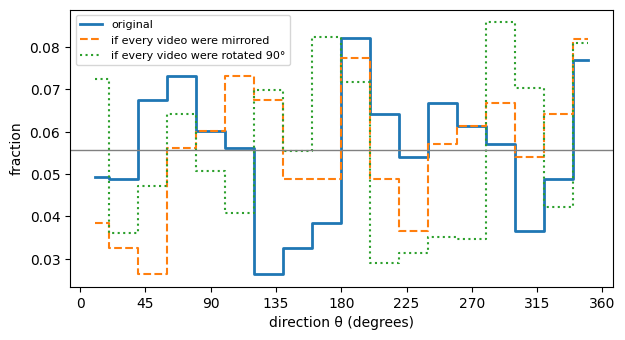

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.6))
centers = bins_dir[:-1] + 10
ax.step(centers, h0, where='mid', label='original', lw=2)
ax.step(centers, h_m, where='mid', label='if every video were mirrored', lw=1.5, ls='--')
ax.step(centers, h_r, where='mid', label='if every video were rotated 90°', lw=1.5, ls=':')
ax.axhline(1/18, color='gray', lw=1)
ax.set_xlabel('direction θ (degrees)'); ax.set_ylabel('fraction'); ax.legend(fontsize=8)
ax.set_xticks(range(0, 361, 45)); plt.show()

### Sample training videos (sanity check)

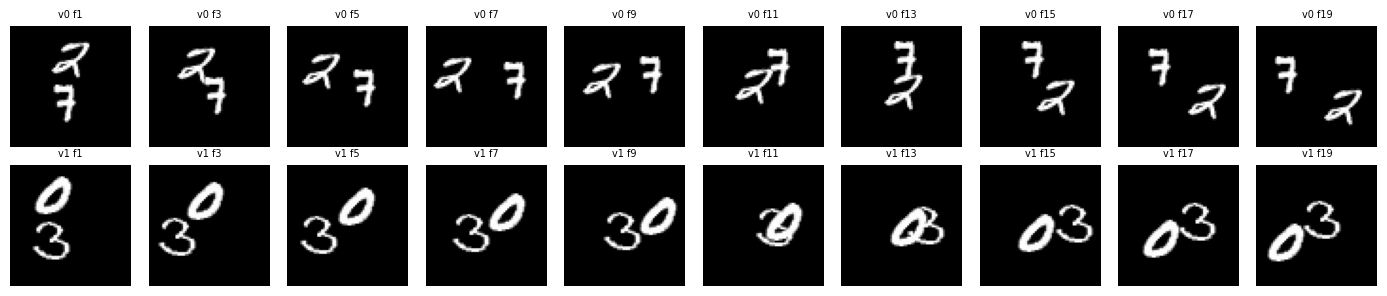

In [11]:
fig, axes = plt.subplots(2, 10, figsize=(14, 3))
for r, vid in enumerate([0, 1]):
    for c in range(10):
        axes[r, c].imshow(train_u8[vid, c * 2, 0], cmap='gray'); axes[r, c].axis('off')
        axes[r, c].set_title(f'v{vid} f{c*2+1}', fontsize=7)
plt.tight_layout(); plt.show()

#  Q2 PART 2 — Baseline ConvLSTM (model A)

In [12]:
import copy, random
import torch.nn as nn
import torch.nn.functional as F

CKPT_DIR = os.path.join(ROOT, 'checkpoints')
GIF_DIR  = os.path.join(ROOT, 'gifs')
os.makedirs(CKPT_DIR, exist_ok=True); os.makedirs(GIF_DIR, exist_ok=True)

EPOCHS, BATCH, LR = 30, 32, 1e-3
SEEDS = (0, 1)
USE_AMP = torch.cuda.is_available()      # mixed precision on GPU (state this in the report)
torch.backends.cudnn.benchmark = True

# whole dataset on the GPU as uint8 (~820 MB) -> fast window gathering
train_dev = train_u8.to(device)
val_dev   = val_u8.to(device)
test_dev  = test_u8.to(device)

def fmt(v):
    """3 significant figures; scientific notation below 1e-3."""
    if v == 0: return '0'
    return f'{v:.2e}' if abs(v) < 1e-3 else f'{v:#.3g}'

HW = torch.cuda.get_device_name(0) if torch.cuda.is_available() else platform.processor()
print('hardware:', HW, '| AMP:', USE_AMP)

hardware: Tesla T4 | AMP: True


In [13]:
class ConvLSTMCell(nn.Module):
    """[i,f,o,g] = Conv([u, h_prev]); c = s(f)*c_prev + s(i)*tanh(g); h = s(o)*tanh(c)."""
    def __init__(self, in_ch, hid, k=3, dilation=1):
        super().__init__()
        self.hid = hid
        pad = dilation * (k - 1) // 2
        self.conv = nn.Conv2d(in_ch + hid, 4 * hid, k, stride=1, padding=pad,
                              dilation=dilation, bias=True)

    def forward(self, u, state):
        h, c = state
        i, f, o, g = torch.chunk(self.conv(torch.cat([u, h], dim=1)), 4, dim=1)
        c = torch.sigmoid(f) * c + torch.sigmoid(i) * torch.tanh(g)
        h = torch.sigmoid(o) * torch.tanh(c)
        return h, c


class ConvLSTMForecaster(nn.Module):
    """Model A with default settings; reused later for model D."""
    def __init__(self, patch=4, hid=64, k=3, dilations=(1, 1)):
        super().__init__()
        self.patch, self.hid = patch, hid
        ch = patch * patch
        self.cell1 = ConvLSTMCell(ch,  hid, k, dilations[0])
        self.cell2 = ConvLSTMCell(hid, hid, k, dilations[1])
        self.out = nn.Conv2d(hid, ch, kernel_size=1, bias=True)

    def step(self, frame, s1, s2):
        u = F.pixel_unshuffle(frame, self.patch)             # (B,1,64,64) -> (B,16,16,16)
        s1 = self.cell1(u, s1)
        s2 = self.cell2(s1[0], s2)
        x_next = torch.sigmoid(F.pixel_shuffle(self.out(s2[0]), self.patch))
        return x_next, s1, s2

    def forward(self, X, n_out=5):
        """9-step rollout, no teacher forcing. Returns outputs of steps 5..9."""
        B, T, C, H, W = X.shape
        hs, ws = H // self.patch, W // self.patch
        z = lambda: X.new_zeros(B, self.hid, hs, ws)
        s1, s2 = (z(), z()), (z(), z())
        outs, pred = [], None
        for tau in range(T + n_out - 1):
            u = X[:, tau] if tau < T else pred               # own prediction fed back
            pred, s1, s2 = self.step(u, s1, s2)
            if tau >= T - 1:
                outs.append(pred)
        return torch.stack(outs, dim=1)


def n_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

_mA = ConvLSTMForecaster()
print('model A trainable parameters:', n_params(_mA))
assert n_params(_mA) == 480_784, 'parameter count must be exactly 480,784'
with torch.no_grad():
    print('output shape:', tuple(_mA(torch.rand(2, 5, 1, 64, 64)).shape))
del _mA

model A trainable parameters: 480784
output shape: (2, 5, 1, 64, 64)


In [14]:
def batch_windows(data_u8, vid_idx, t, k, g_idx=None):
    """Returns X (B,5,1,64,64), Y (B,5,1,64,64) in [0,1], mask (B,5) bool. t is 1-indexed."""
    dev = data_u8.device
    vid_idx, t, k = vid_idx.to(dev), t.to(dev), k.to(dev)
    steps = torch.arange(10, device=dev)
    fr = t[:, None] + k[:, None] * steps[None, :]
    mask_all = fr <= N_FRAMES
    fr = fr.clamp(max=N_FRAMES) - 1
    frames = data_u8[vid_idx[:, None], fr].float() / 255.0
    X, Y = frames[:, :5], frames[:, 5:]
    mask = mask_all[:, 5:]
    Y = Y * mask[:, :, None, None, None]
    if g_idx is not None:
        g_idx = g_idx.to(dev)
        X, Y = X.clone(), Y.clone()
        for gi, g in enumerate(G):
            sel = g_idx == gi
            if sel.any():
                X[sel] = apply_g(X[sel], g); Y[sel] = apply_g(Y[sel], g)
    return X, Y, mask


def masked_video_mse(Yhat, Y, mask):
    """Per video: mean over pixels and available target frames. Returns (B,)."""
    per_frame = ((Yhat.float() - Y) ** 2).mean(dim=(2, 3, 4))
    m = mask.float()
    return (per_frame * m).sum(1) / m.sum(1)


def sample_windows(n, gen, speed_aug=False, sym_aug=False):
    """One random window per video."""
    if speed_aug:
        k = torch.randint(1, 4, (n,), generator=gen)
        t = torch.empty(n, dtype=torch.long)
        for kk in (1, 2, 3):
            sel = k == kk
            starts = torch.tensor(allowed_starts(kk, augmented=True))
            t[sel] = starts[torch.randint(len(starts), (int(sel.sum()),), generator=gen)]
    else:
        k = torch.ones(n, dtype=torch.long)
        starts = torch.tensor(allowed_starts(1, augmented=False))
        t = starts[torch.randint(len(starts), (n,), generator=gen)]
    g = torch.randint(len(G), (n,), generator=gen) if sym_aug else None
    return t, k, g

_t, _k, _g = sample_windows(4, torch.Generator().manual_seed(0), speed_aug=True, sym_aug=True)
_X, _Y, _m = batch_windows(train_dev, torch.arange(4), _t, _k, _g)
print('t', _t.tolist(), 'k', _k.tolist(), '| X', tuple(_X.shape), 'Y', tuple(_Y.shape))
print('mask', _m.int().tolist())

t [2, 2, 2, 10] k [3, 1, 3, 1] | X (4, 5, 1, 64, 64) Y (4, 5, 1, 64, 64)
mask [[1, 1, 0, 0, 0], [1, 1, 1, 1, 1], [1, 1, 0, 0, 0], [1, 1, 1, 1, 1]]


In [15]:
def train_model(name, seed, make_model, speed_aug=False, sym_aug=False,
                epochs=EPOCHS, verbose=True):
    final_path = os.path.join(CKPT_DIR, f'{name}_s{seed}.pt')
    state_path = os.path.join(CKPT_DIR, f'{name}_s{seed}_state.pt')
    log_path   = os.path.join(RES_DIR,  f'{name}_s{seed}_log.json')
    if os.path.exists(final_path) and os.path.exists(log_path):
        print(f'{name} seed {seed}: already trained, loading.')
        model = make_model().to(device)
        model.load_state_dict(torch.load(final_path, map_location=device))
        return model, json.load(open(log_path))

    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    model = make_model().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    gen = torch.Generator().manual_seed(seed)
    log = dict(name=name, seed=seed, params=n_params(model), hardware=HW, amp=USE_AMP,
               speed_aug=speed_aug, sym_aug=sym_aug, epoch_time=[], train_loss=[], val_E5=[])
    start_ep = 0
    if os.path.exists(state_path):
        st = torch.load(state_path, map_location=device, weights_only=False)
        model.load_state_dict(st['model']); opt.load_state_dict(st['opt'])
        scaler.load_state_dict(st['scaler']); gen.set_state(st['gen'])
        log, start_ep = st['log'], st['epoch'] + 1
        print(f'resuming {name} seed {seed} from epoch {start_ep + 1}')

    N = train_dev.shape[0]
    for ep in range(start_ep, epochs):
        model.train()
        if torch.cuda.is_available(): torch.cuda.synchronize()
        t0 = time.time()
        perm = torch.randperm(N, generator=gen)
        t_all, k_all, g_all = sample_windows(N, gen, speed_aug, sym_aug)
        tot, nb = 0.0, 0
        for b in range(0, N, BATCH):
            idx = perm[b:b + BATCH]
            X, Y, m = batch_windows(train_dev, idx, t_all[idx], k_all[idx],
                                    None if g_all is None else g_all[idx])
            with torch.autocast('cuda', dtype=torch.float16, enabled=USE_AMP):
                Yhat = model(X)
            loss = masked_video_mse(Yhat, Y, m).mean()
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update()
            tot += loss.item(); nb += 1
        if torch.cuda.is_available(): torch.cuda.synchronize()
        log['epoch_time'].append(time.time() - t0)
        log['train_loss'].append(tot / nb)
        log['val_E5'].append(evaluate(model, val_dev)['E5'])
        torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), scaler=scaler.state_dict(),
                        gen=gen.get_state(), log=log, epoch=ep), state_path)
        if verbose:
            print(f'{name} s{seed} | epoch {ep + 1:2d}/{epochs} | train {log["train_loss"][-1]:.5f} '
                  f'| val E5 {log["val_E5"][-1]:.5f} | {log["epoch_time"][-1]:.1f}s')

    torch.save(model.state_dict(), final_path)
    log['train_time_per_epoch'] = float(np.mean(log['epoch_time']))
    json.dump(log, open(log_path, 'w'), indent=1)
    if os.path.exists(state_path): os.remove(state_path)
    return model, log

In [16]:
@torch.no_grad()
def predict(model, X, bs=128):
    model.eval(); out = []
    for b in range(0, X.shape[0], bs):
        with torch.autocast('cuda', dtype=torch.float16, enabled=USE_AMP):
            out.append(model(X[b:b + bs]).float())
    return torch.cat(out)

def get_split_windows(data_dev, t=1, k=1, g=None):
    n = data_dev.shape[0]
    tt = torch.full((n,), t, dtype=torch.long); kk = torch.full((n,), k, dtype=torch.long)
    X, Y, m = batch_windows(data_dev, torch.arange(n), tt, kk)
    if g is not None:
        X, Y = apply_g(X, g), apply_g(Y, g)
    return X, Y, m

def per_video_h_mse(Yhat, Y):
    return ((Yhat.float() - Y) ** 2).mean(dim=(2, 3, 4))

def summarise(mse_vh, mask):
    mh = mse_vh.mean(0).cpu().numpy()
    d = {f'MSE{h + 1}': float(mh[h]) for h in range(5) if mask[h]}
    if mask.all(): d['E5'] = float(mh.mean())
    d['E2'] = float(mh[:2].mean())
    return d

def predictor_outputs(kind, model, X):
    if kind == 'blank':     return torch.zeros_like(X)
    if kind == 'copy_last': return X[:, -1:].expand_as(X).contiguous()
    return predict(model, X)

def evaluate(model, data_dev, t=1, k=1, kind='model'):
    X, Y, m = get_split_windows(data_dev, t, k)
    return summarise(per_video_h_mse(predictor_outputs(kind, model, X), Y), m[0])

@torch.no_grad()
def inference_time(model, data_dev, bs=32, n_rep=1):
    X, _, _ = get_split_windows(data_dev, 1, 1)
    model.eval(); total = 0.0
    for _ in range(n_rep):
        for b in range(0, X.shape[0], bs):
            xb = X[b:b + bs]
            if torch.cuda.is_available(): torch.cuda.synchronize()
            t0 = time.time()
            with torch.autocast('cuda', dtype=torch.float16, enabled=USE_AMP):
                _ = model(xb)
            if torch.cuda.is_available(): torch.cuda.synchronize()
            total += time.time() - t0
    return total / n_rep

print('baselines on test (1x, t=1):')
print('  blank    ', {k: fmt(v) for k, v in evaluate(None, test_dev, kind='blank').items()})
print('  copy-last', {k: fmt(v) for k, v in evaluate(None, test_dev, kind='copy_last').items()})

baselines on test (1x, t=1):
  blank     {'MSE1': '0.0426', 'MSE2': '0.0426', 'MSE3': '0.0426', 'MSE4': '0.0425', 'MSE5': '0.0425', 'E5': '0.0426', 'E2': '0.0426'}
  copy-last {'MSE1': '0.0492', 'MSE2': '0.0604', 'MSE3': '0.0669', 'MSE4': '0.0708', 'MSE5': '0.0732', 'E5': '0.0641', 'E2': '0.0548'}


In [17]:
models_A, logs_A = {}, {}
for s in SEEDS:
    models_A[s], logs_A[s] = train_model('A', s, lambda: ConvLSTMForecaster())
    print(f'model A seed {s}: mean epoch time {logs_A[s]["train_time_per_epoch"]:.1f}s')

A s0 | epoch  1/30 | train 0.04612 | val E5 0.03932 | 9.6s
A s0 | epoch  2/30 | train 0.03967 | val E5 0.03855 | 7.1s
A s0 | epoch  3/30 | train 0.03870 | val E5 0.03733 | 7.0s
A s0 | epoch  4/30 | train 0.03716 | val E5 0.03547 | 9.3s
A s0 | epoch  5/30 | train 0.03531 | val E5 0.03395 | 7.0s
A s0 | epoch  6/30 | train 0.03364 | val E5 0.03258 | 6.8s
A s0 | epoch  7/30 | train 0.03231 | val E5 0.03143 | 6.8s
A s0 | epoch  8/30 | train 0.03131 | val E5 0.03041 | 6.7s
A s0 | epoch  9/30 | train 0.03049 | val E5 0.02983 | 6.8s
A s0 | epoch 10/30 | train 0.02993 | val E5 0.02963 | 7.0s
A s0 | epoch 11/30 | train 0.02947 | val E5 0.02881 | 7.4s
A s0 | epoch 12/30 | train 0.02893 | val E5 0.02839 | 6.8s
A s0 | epoch 13/30 | train 0.02857 | val E5 0.02797 | 6.7s
A s0 | epoch 14/30 | train 0.02800 | val E5 0.02761 | 6.7s
A s0 | epoch 15/30 | train 0.02765 | val E5 0.02718 | 6.7s
A s0 | epoch 16/30 | train 0.02730 | val E5 0.02692 | 6.7s
A s0 | epoch 17/30 | train 0.02688 | val E5 0.02695 | 6.

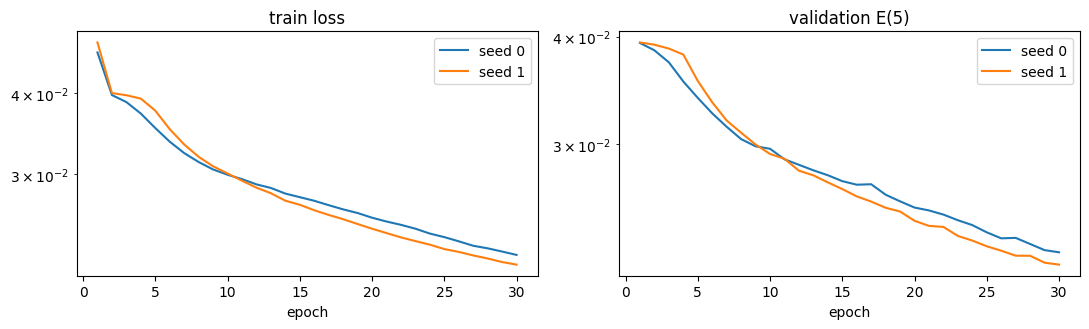

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for s in SEEDS:
    axes[0].plot(range(1, EPOCHS + 1), logs_A[s]['train_loss'], label=f'seed {s}')
    axes[1].plot(range(1, EPOCHS + 1), logs_A[s]['val_E5'], label=f'seed {s}')
axes[0].set_title('train loss'); axes[1].set_title('validation E(5)')
for a in axes: a.set_xlabel('epoch'); a.legend(); a.set_yscale('log')
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'curves_A.png'), dpi=150); plt.show()

In [19]:
def mean_pair(vals):
    return f'{fmt(np.mean(vals))} ({fmt(vals[0])}, {fmt(vals[1])})'

res_A = {s: evaluate(models_A[s], test_dev) for s in SEEDS}
res_blank = evaluate(None, test_dev, kind='blank')
res_copy  = evaluate(None, test_dev, kind='copy_last')
cols = ['MSE1', 'MSE2', 'MSE3', 'MSE4', 'MSE5', 'E5']

table2 = [['Model A'] + [mean_pair([res_A[s][c] for s in SEEDS]) for c in cols] + ['480,784'],
          ['Blank']     + [fmt(res_blank[c]) for c in cols] + ['0'],
          ['Copy-last'] + [fmt(res_copy[c])  for c in cols] + ['0']]
print(f'{"":10s} | ' + ' | '.join(f'{c:24s}' for c in cols + ['params']))
for row in table2:
    print(f'{row[0]:10s} | ' + ' | '.join(f'{v:24s}' for v in row[1:]))
json.dump(dict(table2=table2, raw=dict(A=res_A, blank=res_blank, copy_last=res_copy)),
          open(os.path.join(RES_DIR, 'table2.json'), 'w'), indent=1)

           | MSE1                     | MSE2                     | MSE3                     | MSE4                     | MSE5                     | E5                       | params                  
Model A    | 0.0171 (0.0172, 0.0169)  | 0.0205 (0.0208, 0.0202)  | 0.0228 (0.0232, 0.0225)  | 0.0246 (0.0251, 0.0242)  | 0.0264 (0.0269, 0.0259)  | 0.0223 (0.0226, 0.0219)  | 480,784                 
Blank      | 0.0426                   | 0.0426                   | 0.0426                   | 0.0425                   | 0.0425                   | 0.0426                   | 0                       
Copy-last  | 0.0492                   | 0.0604                   | 0.0669                   | 0.0708                   | 0.0732                   | 0.0641                   | 0                       


test videos with strongest overlap in target frames (index within test split): [851, 216, 313, 805, 62, 405, 113, 63, 207, 836]


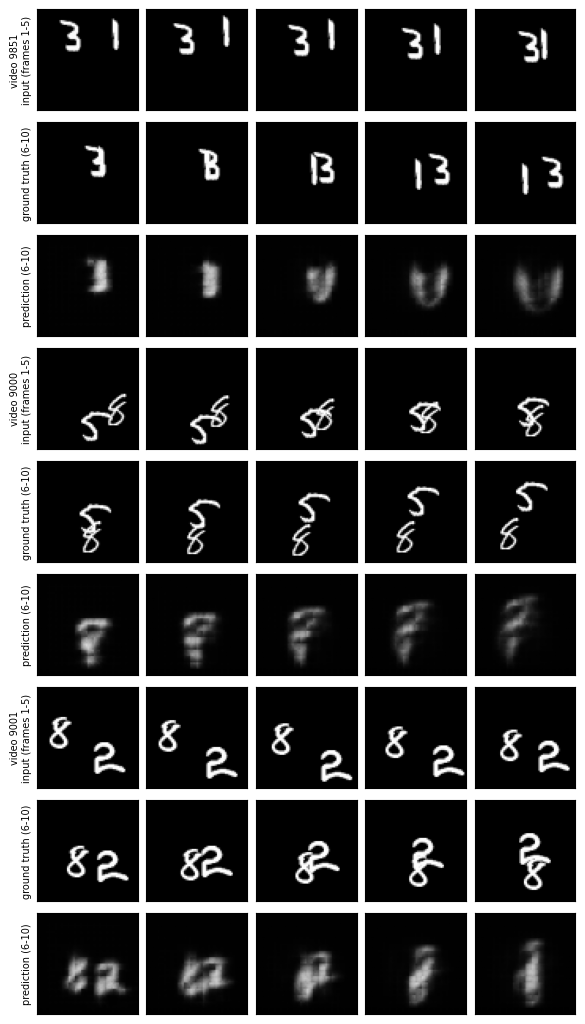

Figure 2 videos (dataset index): [9851, 9000, 9001]


In [22]:
Xte, Yte, mte = get_split_windows(test_dev, 1, 1)
area = (torch.cat([Xte, Yte], 1) > 0.2).float().sum(dim=(2, 3, 4))
drop = 1 - area[:, 5:].min(1).values / area.median(1).values
overlap_ids = torch.argsort(drop, descending=True)[:10].tolist()
print('test videos with strongest overlap in target frames (index within test split):', overlap_ids)

FIG2_IDS = [overlap_ids[0], 0, 1]      # one with overlap + two ordinary
Yhat_A0 = predict(models_A[0], Xte[FIG2_IDS])

fig, axes = plt.subplots(3 * len(FIG2_IDS), 5, figsize=(7, 1.45 * 3 * len(FIG2_IDS)))
for v, vid in enumerate(FIG2_IDS):
    rows = [('input (frames 1-5)', Xte[vid]), ('ground truth (6-10)', Yte[vid]),
            ('prediction (6-10)', Yhat_A0[v])]
    for r, (lab, seq) in enumerate(rows):
        for c in range(5):
            ax = axes[3 * v + r, c]
            ax.imshow(seq[c, 0].cpu(), cmap='gray', vmin=0, vmax=1)
            ax.set_xticks([]); ax.set_yticks([])
            if c == 0: ax.set_ylabel(f'video {9000 + vid}\n{lab}' if r == 0 else lab, fontsize=7)
plt.subplots_adjust(wspace=0.04, hspace=0.12)
plt.savefig(os.path.join(FIG_DIR, 'figure2_modelA.png'), dpi=200, bbox_inches='tight')
plt.show()
print('Figure 2 videos (dataset index):', [9000 + v for v in FIG2_IDS])

In [23]:
for s in SEEDS: inference_time(models_A[s], test_dev)
inf_A = {s: inference_time(models_A[s], test_dev, n_rep=3) for s in SEEDS}
for s in SEEDS:
    print(f'seed {s}: train {logs_A[s]["train_time_per_epoch"]:.1f} s/epoch | '
          f'inference (1,000 test videos) {inf_A[s]:.3f} s')
json.dump(dict(hardware=HW, amp=USE_AMP,
               train_time={s: logs_A[s]['train_time_per_epoch'] for s in SEEDS},
               inference_time=inf_A),
          open(os.path.join(RES_DIR, 'timing_A.json'), 'w'), indent=1)

seed 0: train 7.0 s/epoch | inference (1,000 test videos) 0.322 s
seed 1: train 6.7 s/epoch | inference (1,000 test videos) 0.315 s
